# 08 · Error control and certification

**Level:** advanced · **Prerequisites:** [07](07_how_pizzetti_computes_a_light_curve.ipynb) · **Run time:** ~1 min

**Covers:** `series_tol`, the proven bound of the interior series, `limb="proven"` and `return_certified=True`, the certified fraction against radius ratio and tolerance, an independent 40-digit check

pizzetti's interior series carries a proven truncation bound, and the limb can carry one too. Here we set the tolerance, check that it holds, and find out which samples of a light curve are certified.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mpmath as mp
import pizzetti
from pizzetti import occult, series_cut

## 1. `series_tol`: one number, one cut

`series_tol` (default 10⁻⁹ of the stellar flux) is the largest flux error allowed for the interior series.
Because all terms of the series beyond the truncation have the same sign, the remainder has a closed-form
bound; pizzetti uses the series only where that bound is below `series_tol`. A tighter tolerance moves the
cut z_c inwards and hands more samples to the limb methods.

In [2]:
rp, law, u = 0.1, "nonlinear", [0.5, 0.1, 0.1, -0.1]
z = np.linspace(0, 1 + rp, 6000)
ref = occult(z, rp, u, law, series_tol=0.0, limb="quadrature")
print(f"{'series_tol':>10s} {'z_c':>7s} {'max |error|, z <= z_c':>22s}")
for tol in (1e-6, 1e-9, 1e-12):
    zc = series_cut(rp, law, u, series_tol=tol)
    f = occult(z, rp, u, law, series_tol=tol, limb="quadrature")      # quadrature at the limb: isolates the series error
    print(f"{tol:10.0e} {zc:7.4f} {np.max(np.abs(f - ref)[z <= zc]):22.2e}")

series_tol     z_c  max |error|, z <= z_c
     1e-06  0.8849               3.98e-07
     1e-09  0.8203               7.25e-10
     1e-12  0.7105               8.66e-13


The actual error is just below the tolerance: the bound is tight. `series_tol=0` switches the series off.

## 2. Certified light curves

With `limb="proven"` the limb uses piecewise polynomials whose error is also proven to be at most
`series_tol`. `return_certified=True` returns, for every sample, whether its flux carries the proof
(interior series, proven limb pieces, closed forms, and out-of-transit samples). Pieces that cannot be
certified (large planets, or very tight tolerances near z = rp) fall back to quadrature and are reported as
not certified.

In [3]:
f, cert = occult(z, rp, u, law, series_tol=1e-9, limb="proven", return_certified=True)
print(f"certified: {cert.mean():.1%} of the samples, largest error {np.max(np.abs(f - ref)):.1e}")
print(f"largest error among certified samples: {np.max(np.abs(f - ref)[cert]):.1e} (bound 1e-9)")

certified: 100.0% of the samples, largest error 7.2e-10
largest error among certified samples: 7.2e-10 (bound 1e-9)


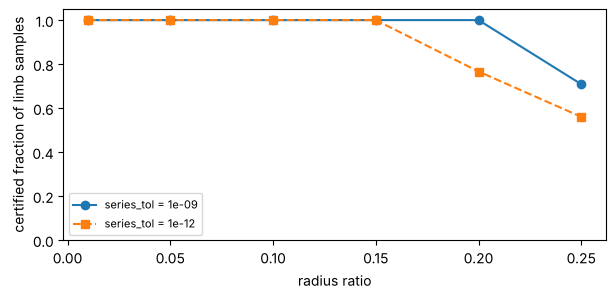

In [4]:
ps = (0.01, 0.05, 0.1, 0.15, 0.2, 0.25)
fig, ax = plt.subplots(figsize=(7, 3))
for tol, mk in ((1e-9, "o-"), (1e-12, "s--")):
    frac = []
    for p in ps:
        zp = np.linspace(series_cut(p, law, u, series_tol=tol), 1 + p, 400)[1:-1]
        _, c = occult(zp, p, u, law, series_tol=tol, limb="proven", return_certified=True)
        frac.append(c.mean())
    ax.plot(ps, frac, mk, label=f"series_tol = {tol:.0e}")
ax.set(xlabel="radius ratio", ylabel="certified fraction of limb samples", ylim=(0, 1.05)); ax.legend(fontsize=8);

For a tolerance of 10⁻⁹ every limb sample is certified up to radius ratios of about 0.2; at 10⁻¹² up to about
0.15. The proof costs 5–60 ms of set-up per light curve, so `"proven"` is opt-in.

## 3. Check it yourself: a 40-digit reference

The flux deficit is the integral of the intensity over the occulted part of the stellar disk. By Green's
theorem it becomes a one-dimensional integral along the occulter's rim, which mpmath can evaluate to 40 digits.
This reference is independent of pizzetti's series and limb methods.

In [5]:
def flux_ref(z, k, alphas, coefs, dps=40):
    with mp.workdps(dps):
        z, k = mp.mpf(z), mp.mpf(k)
        gs = [mp.mpf(a) / 2 for a in alphas]
        cs = [mp.mpf(c) for c in coefs]
        total = 2 * mp.pi * sum(c / (2 * g + 2) for c, g in zip(cs, gs))
        if z >= 1 + k:
            return 1.0
        h = lambda x, g: mp.mpf(1) / 2 if x == 0 else (1 - (1 - min(x, 1)) ** (g + 1)) / (2 * (g + 1) * x)
        th = mp.acos(max(min((1 + z * z - k * k) / (2 * z), 1), -1)) if z > 0 else mp.mpf(0)
        blocked = sum(c * th / (g + 1) for c, g in zip(cs, gs))
        c0 = (1 - z * z - k * k) / (2 * z * k) if z > 0 else mp.mpf(1)    # z = 0: the whole rim is inside
        if c0 > -1:
            t0 = mp.acos(min(c0, 1))
            def fr(t):
                r2 = z * z + k * k + 2 * z * k * mp.cos(t)
                return 2 * k * (k + z * mp.cos(t)) * sum(c * h(r2, g) for c, g in zip(cs, gs))
            blocked += mp.quad(fr, [t0 + (mp.pi - t0) * x for x in (0, mp.mpf(10)**-8, mp.mpf(10)**-4, mp.mpf(1) / 100, mp.mpf(1) / 10, mp.mpf(1) / 2, 1)])
        return float(1 - blocked / total)

alphas, coefs = [0.0, 0.5, 1.0, 1.5, 2.0], [1 - sum(u)] + u        # the nonlinear law as a sum of powers of mu
zs = np.concatenate([[0.0, 0.5, 0.85], 1 - rp + np.array([-1e-9, 1e-9, 0.05]), 1 + rp - np.array([1e-10, 1e-4])])
r40 = np.array([flux_ref(x, rp, alphas, coefs) for x in zs])
for m in ("fast", "proven", "quadrature"):
    print(f'limb="{m}":{"":{12 - len(m)}s} max |pizzetti - 40-digit| = {np.max(np.abs(occult(zs, rp, u, law, limb=m) - r40)):.1e}')

limb="fast":         max |pizzetti - 40-digit| = 1.1e-16
limb="proven":       max |pizzetti - 40-digit| = 9.9e-11
limb="quadrature":   max |pizzetti - 40-digit| = 1.1e-16


## What you learned

- `series_tol` is a proven bound for the interior series, and a tight one.
- `limb="proven"` with `return_certified=True` extends the proof to the limb and tells you which samples carry it.
- Every number can be checked against an independent 40-digit Green's-theorem reference in a few lines.

**Next:** [09 · Performance](09_performance.ipynb)